# Data audit and target limitations

The supplied target is a next-12-month array event. Missing labels are inference rows. Account cancellation, observation timestamps and label maturity are unverified. Anomaly causes are unknown.

In [1]:
from pathlib import Path
import sys
import json
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/config.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.config import DATA_PATH, OUTPUTS, PRIMARY_SCORE
from src.data_cleaning import validate_raw_frame, clean_dataset, TARGET
from src.model_training import latest_run, load_bundle, predict_bundle, sha256_file, frame_hash
from src.backtesting import read_evidence
plt.rcParams.update({'figure.figsize': (9, 4), 'figure.dpi': 110})
run_dir = latest_run()
oof, manifest = read_evidence(run_dir)
bundle, _ = load_bundle(run_dir)
for name, expected in manifest['source_sha256'].items():
    assert sha256_file(ROOT / 'src' / name) == expected, f'Source changed since training: {name}'
for name, expected in manifest['warehouse_source_sha256'].items():
    assert sha256_file(ROOT / 'sql' / name) == expected, f'SQL changed since training: {name}'
assert sha256_file(run_dir / 'training_snapshot.csv') == manifest['training_snapshot_sha256']
display(pd.Series({
    'training_run': manifest['run_id'], 'model_version': manifest['model_version'],
    'training_created_at_utc': manifest['created_at_utc'],
    'feature_reference_date': bundle['reference_date'],
    'validation_source': manifest['prediction_source'],
}).to_frame('saved evidence'))
print('Notebook review updated: 2026-10-11. Results come from the saved training run above.')


,saved evidence
training_run,f0095e2660d447bd9df382f307062afb
model_version,v2.1.0-grouped-sigmoid-unweighted
training_created_at_utc,2026-10-11T09:40:45.905842+00:00
feature_reference_date,2026-10-01
validation_source,grouped_oof


Notebook review updated: 2026-10-11. Results come from the saved training run above.


In [2]:
raw = validate_raw_frame(DATA_PATH)
labeled, unlabeled, audit = clean_dataset(raw)
display(pd.Series(audit, name='value').to_frame())
display(raw.describe(include='all').T)
assert len(labeled) + len(unlabeled) == len(raw)
assert set(labeled[TARGET]) == {0, 1}
assert frame_hash(validate_raw_frame(labeled)) == manifest['labeled_input_sha256']


,value
total_rows,2000.00000
over_utilized_count,862.00000
over_utilized_pct,43.10000
negative_profit_count,58.00000
negative_profit_pct,2.90000
missing_churn_count,116.00000
missing_churn_pct,5.80000
unknown_expansion_count,111.00000
unknown_expansion_pct,5.55000
max_raw_utilization,1.45000


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
account_id,2000,1000,ACC_1000,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
array_id,2000,2000,ARR_5000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contract_end_date,2000,NaN,NaN,NaN,2028-02-12 12:00:00,2026-10-01 00:00:00,2027-06-07 18:00:00,2028-02-12 12:00:00,2028-10-19 06:00:00,2029-06-26 00:00:00,NaN
historical_15yr_net_profit_usd,2000.0,NaN,NaN,NaN,2152844.782,-93780.0,996693.75,2134327.5,3277239.5,4498824.0,1330932.441042
current_capacity_tb,2000.0,NaN,NaN,NaN,1282.771,53.0,673.5,1305.5,1880.0,2498.0,699.754635
utilization_rate_pct,2000.0,NaN,NaN,NaN,0.91704,0.35,0.66,0.93,1.18,1.45,0.312321
static_baseline_churn_rate,2000.0,NaN,NaN,NaN,0.05,0.05,0.05,0.05,0.05,0.05,0.0
churn_event_next_12m,1884.0,NaN,NaN,NaN,0.158174,0.0,0.0,0.0,0.0,1.0,0.365001
expansion_potential_signal,2000,4,Low,841,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Label grain

Sibling arrays may have discordant labels. Neither one array retiring nor both arrays leaving proves commercial account loss.

In [3]:
accounts = labeled.groupby('account_id')[TARGET].agg(['count', 'nunique'])
fully_labeled = accounts[accounts['count'] == 2]
print('Fully labeled two-array accounts:', len(fully_labeled))
print('Discordant-label accounts:', int((fully_labeled['nunique'] > 1).sum()))
print('Unlabeled rows are excluded from supervised fitting:', len(unlabeled))


Fully labeled two-array accounts: 889
Discordant-label accounts: 224
Unlabeled rows are excluded from supervised fitting: 116


## Preserved anomalies

Utilization is a fraction, so 1.45 means 145%. Profit remains signed; signed log avoids fitting a global minimum. UNKNOWN is nominal. Schema validation rejects unsupported categories, dates, labels, invalid capacity and duplicate keys.

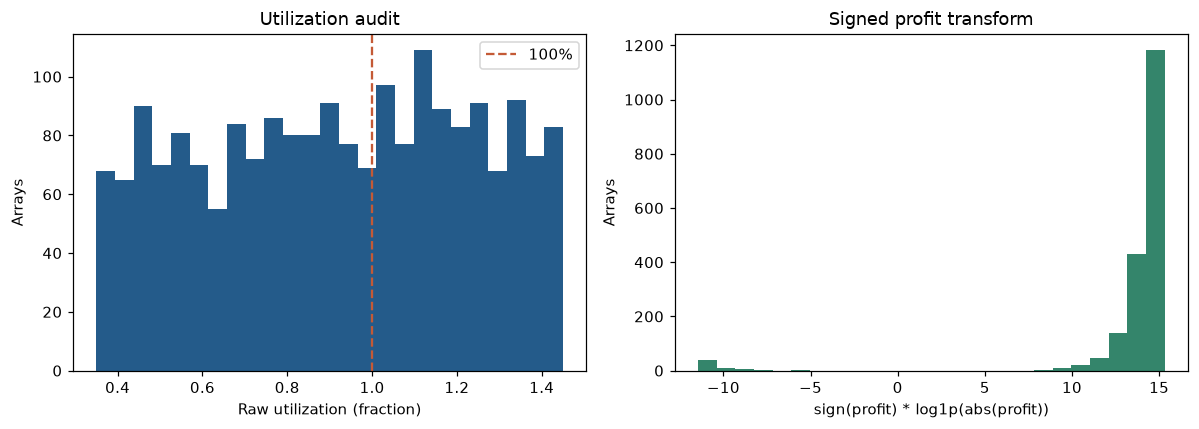

,arrays
expansion_potential_signal,
High,426
Low,841
Medium,622
UNKNOWN,111


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(raw.utilization_rate_pct, bins=25, color='#245b8a')
axes[0].axvline(1, color='#c45a36', linestyle='--', label='100%')
axes[0].set(xlabel='Raw utilization (fraction)', ylabel='Arrays', title='Utilization audit')
axes[0].legend()
axes[1].hist(labeled.signed_log_profit, bins=25, color='#34856b')
axes[1].set(xlabel='sign(profit) * log1p(abs(profit))', ylabel='Arrays', title='Signed profit transform')
plt.tight_layout()
plt.show()
display(raw.groupby('expansion_potential_signal', dropna=False).size().rename('arrays').to_frame())


## Cleaning and input contract

Account/array identifiers retain leading zeros when read from CSV. Dates and finite numeric values are required; capacity must be positive and utilization nonnegative. Labels can be 0, 1 or absent. Missing expansion tags become UNKNOWN, and unsupported values fail validation. Utilization above 100% and negative profit remain visible through explicit flags. The integer expansion export code is excluded from model features; four nominal indicators are used instead. No target, identifier or historical batch minimum enters the feature matrix.

In [5]:
anomaly_examples = labeled.loc[
    labeled.is_over_utilized_raw.eq(1) | labeled.is_negative_profit.eq(1),
    ['account_id', 'array_id', 'raw_utilization_rate_pct', 'utilization_capped',
     'is_over_utilized_raw', 'historical_15yr_net_profit_usd', 'signed_log_profit',
     'is_negative_profit', 'expansion_potential_signal']
]
display(anomaly_examples.head(8))
assert labeled.utilization_capped.le(1).all()
assert np.allclose(labeled.signed_log_profit,
                   np.sign(labeled.historical_15yr_net_profit_usd) *
                   np.log1p(labeled.historical_15yr_net_profit_usd.abs()))
print('Repeated arrays per account are handled by grouping folds, not by merging their labels.')


,account_id,array_id,raw_utilization_rate_pct,utilization_capped,is_over_utilized_raw,historical_15yr_net_profit_usd,signed_log_profit,is_negative_profit,expansion_potential_signal
2,ACC_1002,ARR_5002,1.28,1.00,1,2790632,14.841779,0,Low
4,ACC_1004,ARR_5004,1.22,1.00,1,2881167,14.873706,0,Low
6,ACC_1006,ARR_5006,1.24,1.00,1,2407913,14.694271,0,High
7,ACC_1007,ARR_5007,1.02,1.00,1,4046181,15.213284,0,Medium
8,ACC_1008,ARR_5008,0.56,0.56,0,-5551,-8.621914,1,Low
10,ACC_1010,ARR_5010,1.10,1.00,1,4088851,15.223775,0,Medium
11,ACC_1011,ARR_5011,1.05,1.00,1,4259122,15.264574,0,Low
13,ACC_1013,ARR_5013,1.34,1.00,1,3843183,15.161812,0,High


Repeated arrays per account are handled by grouping folds, not by merging their labels.


## Financial quantities

These are sums of signed historical profit. They are not expected losses or future CLV.

In [6]:
display(pd.DataFrame({
    'population': ['all arrays', 'labeled arrays'],
    'arrays': [len(raw), len(labeled)],
    'signed_historical_profit_usd': [raw.historical_15yr_net_profit_usd.sum(),
                                   labeled.historical_15yr_net_profit_usd.sum()]
}))


,population,arrays,signed_historical_profit_usd
0,all arrays,2000,4305689564
1,labeled arrays,1884,4053131625


## Data still needed

The fixes do not establish event definitions or label maturity. Account cancellation rules, observation dates, product-family mappings, dated expansion outcomes, event/censoring histories and forward cash flows remain required for the corresponding business analyses. The frozen feature reference date shown above is a training setting; updating a notebook does not advance it.